# Comparing scanpath metrics: ScanMatch vs. Eyenalysis vs. DTW

**Motivation.** Model-vs-human scanpath similarity is usually reported with a single metric. This notebook checks whether different, established scanpath metrics lead to the same conclusions, by scoring the same fixation data with three metrics (plus a length-normalized DTW variant):

| Metric | Implementation | Direction |
|---|---|---|
| **ScanMatch** (Cristino et al., 2010) | `VisualSearchAsymmetry/vs_saccade_exp/scanmatch.py` (NumPy port, validated bit-for-bit against the original MATLAB `ScanMatch.m`) | higher = more similar |
| **Eyenalysis** (Mathôt et al., 2012) | `eyefeatures.features.dist.calc_eye_dist` (PyPI `eyefeatures`) | lower = more similar |
| **Dynamic Time Warping** | `fastdtw.fastdtw` with Euclidean point distance (PyPI `fastdtw`) | lower = more similar |
| **DTW (normalized)** | as DTW, divided by the warping-path length | lower = more similar |

**Sources compared against humans:**
- **Humans**: human-vs-human baseline over all pairs of subjects.
- **IVSN**: the original fixations published by the authors.
- **eccNET (original)**: the original parametrization.
- **eccNET (new param.)**: `eccNET_altParam`, the parametrization from `VisualSearchAsymmetry/notebooks/runExp_eccNet_with_parametrization.ipynb`.

**Datasets.** **Waldo**, **ObjArr** (object arrays) and **NaturalDesign**, selected via `DATASETS`.

**ObjArr specifics.** Each display has 6 objects around the screen center, so every fixation lies on one of 7 fixed positions (center + 6 objects), and a scanpath has at most 7 fixations. Two preprocessing steps apply to ObjArr only (Section 3):
- The stored coordinates are layout "slots" in (x, y) order. They are mapped to the actual screen positions with the `xtrans`/`ytrans` tables from `score_analysis.py` (a uniform scaling of about 0.55 around the center), so all distances are in screen pixels like for Waldo.
- Every ObjArr scanpath, human or model, starts with the same center fixation. It is dropped, because it would be a guaranteed match that dilutes the differences between sources.

**Environment.** Run this notebook with the `scanpath_metrics` kernel (Python 3.11 with `eyefeatures`, `fastdtw`). `eyefeatures` cannot be installed into the TensorFlow env `vsa_nips_klab`: TF 2.13 requires `numpy<=1.24.3`, `eyefeatures` pins `numpy==1.26.0`. Model runs therefore go through a subprocess in `vsa_nips_klab` (Section 2).

## 1. Setup

In [1]:
%matplotlib inline
import itertools
import os
import pathlib
import subprocess
import sys

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eyefeatures.features.dist import calc_eye_dist
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean
from tqdm.auto import tqdm

# Locate the Codebase root (parent of InvariantSearch/ and VisualSearchAsymmetry/)
# from the notebook's cwd, so the notebook works no matter where Jupyter was started.
_cwd = pathlib.Path.cwd().resolve()
CODEBASE = next(p for p in [_cwd] + list(_cwd.parents)
                if (p / "InvariantSearch").is_dir() and (p / "VisualSearchAsymmetry").is_dir())

SACCADE_DIR = CODEBASE / "VisualSearchAsymmetry" / "vs_saccade_exp"
OUT_DIR = CODEBASE / "InvariantSearch" / "notebooks" / "out" / "scanpath_metrics"

# scanmatch.py only depends on NumPy, so it can be imported directly here.
sys.path.insert(0, str(SACCADE_DIR))
import scanmatch

DATASETS = ["Waldo", "ObjArr", "NaturalDesign"]

# Display label -> file stem in out/<dataset>/{fix,ifix}/
MODELS = {
    "IVSN": "IVSN",
    "eccNET (original)": "eccNET",
    "eccNET (new param.)": "eccNET_altParam",
}
HUMAN_LABEL = "Humans"
HUMAN_STEM = "human_all"

N_SUBJECTS = 15
# Stored fixations are already rescaled to the 1280x1024 eye-tracking screen (runExp.py s_ratio).
SCREEN = {"Waldo": (1280, 1024), "ObjArr": (1280, 1024), "NaturalDesign": (1280, 1024)}  # (Xres, Yres)

# ObjArr stores (x, y) slot coordinates; score_analysis.py maps them to screen positions.
OBJARR_XTRANS = {640: 640, 365: 490, 90: 340, 915: 790, 1190: 940}
OBJARR_YTRANS = {512: 512, 988: 772, 36: 252}
DROP_FIRST_FIX = {"ObjArr"}  # every ObjArr scanpath starts at the screen center

SCANMATCH_XBIN, SCANMATCH_YBIN = 12, 8  # same as score_analysis.py
RECOMPUTE = False  # True ignores the score cache in OUT_DIR
SPP = True  # add-on: Scanpath Plausibility (best match over humans per stimulus), see Section 5

# Colors as in vs_saccade_exp/score_analysis.py, so figures match the existing ones.
COLORS = {HUMAN_LABEL: "#EF553B", "IVSN": "#919191",
          "eccNET (original)": "#00CC96", "eccNET (new param.)": "#636EFA"}

print("Codebase:", CODEBASE)

Codebase: /Users/nadine/Documents/Uni/Hiwi/Codebase


/Users/nadine/anaconda3/envs/scanpath_metrics/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data availability & running missing experiments

Checks that `fix/` and `ifix/` exist for every source. Missing eccNET runs are computed with `run_saccade_experiment` (`vs_saccade_exp/runExp.py`) in a subprocess inside the TensorFlow env `vsa_nips_klab`. IVSN cannot be rerun (no runner in this codebase). For Waldo nothing is missing. On ObjArr and NaturalDesign, `eccNET_altParam` did not exist and is computed here on the first run.

In [2]:
MODEL_ENV = "vsa_nips_klab"

# eccParam of the new parametrization, copied from
# VisualSearchAsymmetry/notebooks/runExp_eccNet_with_parametrization.ipynb (display geometry -> deg2px).
_deg2px = 470 * 0.0194 * (1920 / 332)
ALT_ECC_PARAM = {
    "rf_min": [2] * 5,
    "stride": [2] * 5,
    "ecc_slope": [0, 0, 1/6, 3/6, 5/6],
    "deg2px": [round(_deg2px / 2**i) for i in range(5)],
    "fovea_size": 4,
    "rf_quant": 1,
    "pool_type": "avg",
}

# Python snippet run inside MODEL_ENV with cwd=SACCADE_DIR. runExp.ecc_models[0] is the
# original eccNET model_desc; the new parametrization only swaps eccParam and model_subname.
_RUNNER = """
import runExp
model_desc = dict(runExp.ecc_models[0])
if {ecc_param!r} is not None:
    model_desc.update(eccParam={ecc_param!r}, model_subname={subname!r})
print(runExp.run_saccade_experiment(model_desc, datasets=[{dataset!r}]))
"""
RUN_SPECS = {
    "eccNET": dict(ecc_param=None, subname=""),
    "eccNET_altParam": dict(ecc_param=ALT_ECC_PARAM, subname="_altParam"),
}


def has_fixations(dataset, stem):
    out = SACCADE_DIR / "out" / dataset
    return (out / "fix" / f"{stem}.npy").is_file() and (out / "ifix" / f"I_{stem}.npy").is_file()


def run_missing_experiments(dataset):
    for stem in [HUMAN_STEM] + list(MODELS.values()):
        if has_fixations(dataset, stem):
            continue
        if stem not in RUN_SPECS:
            raise FileNotFoundError(f"No fixations for {stem} on {dataset}, and no runner available for it.")
        print(f"Running {stem} on {dataset} in env {MODEL_ENV} ...")
        script = _RUNNER.format(dataset=dataset, **RUN_SPECS[stem])
        subprocess.run(["conda", "run", "--no-capture-output", "-n", MODEL_ENV, "python", "-c", script],
                       cwd=SACCADE_DIR, check=True)


for dataset in DATASETS:
    run_missing_experiments(dataset)

pd.DataFrame({d: {s: has_fixations(d, s) for s in [HUMAN_STEM] + list(MODELS.values())} for d in DATASETS})

,Waldo,ObjArr,NaturalDesign
human_all,True,True,True
IVSN,True,True,True
eccNET,True,True,True
eccNET_altParam,True,True,True


> **Note:** the ObjArr run of `eccNET_altParam` uses the same `ALT_ECC_PARAM` as Waldo. Its `deg2px` comes from the display geometry, not from the dataset, just like the original eccNET uses `deg2px = 30` for every dataset. The older files `eccNET_altParamSaccade.npy` (Waldo, NaturalDesign) are bit-identical to the original `eccNET.npy`, i.e. that earlier run did not apply the new parametrization. They are not used here.

## 3. Loading fixation data

For ObjArr, `load_fixations` maps the slot coordinates to screen pixels and drops the common start fixation (see the introduction). The fixation counts below are therefore one lower than the stored ones.

In [3]:
def load_fixations(dataset, stem):
    """Returns fix (N, NumFix, 2) in (row, col) = (y, x) pixels and I (N,) fixation counts.
    Entries of fix beyond I[i] are zero padding."""
    out = SACCADE_DIR / "out" / dataset
    fix = np.load(out / "fix" / f"{stem}.npy").astype(float)
    I = np.load(out / "ifix" / f"I_{stem}.npy").reshape(-1).astype(int)
    if dataset == "ObjArr":
        # (x, y) slots -> (row, col) screen pixels; zero padding stays zero.
        x = np.vectorize(lambda v: OBJARR_XTRANS.get(v, 0))(fix[..., 0])
        y = np.vectorize(lambda v: OBJARR_YTRANS.get(v, 0))(fix[..., 1])
        fix = np.stack([y, x], axis=-1).astype(float)
    if dataset in DROP_FIRST_FIX:
        fix, I = fix[:, 1:], I - 1
    return fix, I


def to_xy(fix_row, n):
    """First n fixations of one stimulus as an (n, 2) array of (x, y)."""
    return fix_row[:n, ::-1]


def split_subjects(fix, I, n_subjects):
    """Human data is stacked subject-wise (same indexing as score_analysis.py)."""
    n_stim = fix.shape[0] // n_subjects
    return [(fix[s*n_stim:(s+1)*n_stim], I[s*n_stim:(s+1)*n_stim]) for s in range(n_subjects)]


data = {}
for dataset in DATASETS:
    human_fix, human_I = load_fixations(dataset, HUMAN_STEM)
    data[dataset] = {
        "humans": split_subjects(human_fix, human_I, N_SUBJECTS),
        "human_all": (human_fix, human_I),
        "models": {label: load_fixations(dataset, stem) for label, stem in MODELS.items()},
    }
    assert all(f.shape[0] == data[dataset]["humans"][0][0].shape[0]
               for f, _ in data[dataset]["models"].values()), "stimulus count mismatch"

    counts = {HUMAN_LABEL: human_I, **{label: I for label, (_, I) in data[dataset]["models"].items()}}
    print(dataset)
    display(pd.DataFrame({k: pd.Series(v).describe()[["count", "mean", "min", "max"]] for k, v in counts.items()}).T)

Waldo


,count,mean,min,max
Humans,1005.0,28.565174,1.0,80.0
IVSN,67.0,35.358209,1.0,80.0
eccNET (original),67.0,41.149254,1.0,81.0
eccNET (new param.),67.0,45.179104,1.0,81.0


ObjArr


,count,mean,min,max
Humans,4500.0,3.400000,1.0,6.0
IVSN,300.0,2.870000,1.0,6.0
eccNET (original),300.0,2.593333,1.0,6.0
eccNET (new param.),300.0,2.686667,1.0,6.0


NaturalDesign


,count,mean,min,max
Humans,3600.0,6.319167,1.0,65.0
IVSN,240.0,14.845833,1.0,65.0
eccNET (original),240.0,17.408333,1.0,66.0
eccNET (new param.),240.0,17.108333,1.0,66.0


## 4. Scanpath metrics

All metrics are wrapped with the same per-stimulus signature `metric(fix_a, n_a, fix_b, n_b, dataset) -> float`. Fixations are in pixels of the 1280×1024 screen, so the Eyenalysis and DTW distances are in pixel units (squared pixels for Eyenalysis, see below).

- **ScanMatch** bins fixations into a 12×8 grid, turns each scanpath into a sequence of grid cells, and aligns the two sequences with Needleman-Wunsch. The substitution threshold is estimated from the human saccade amplitudes (`scanmatch.estimate_threshold`), with the same parameters as `score_analysis.ScanpathScorePy`. Range is about [0, 1], **higher = more similar**.
- **Eyenalysis** maps every fixation to its nearest neighbour in the other scanpath (in both directions), sums the distances and normalizes by the longer scanpath. `eyefeatures` uses *squared* Euclidean distances. **Lower = more similar.**
- **DTW** is the minimal summed Euclidean distance over all monotonic alignments of the two sequences (`fastdtw`). It is not length-normalized, so longer scanpaths get larger distances. **Lower = more similar.**
- **DTW (normalized)** divides the DTW distance of each scanpath pair by the length of its warping path (number of aligned fixation pairs, between max(n, m) and n + m − 1), i.e. the mean distance per aligned pair. This removes most of the length effect while keeping the order sensitivity. MSS and SPP are then computed from these per-pair values. **Lower = more similar.**

In [4]:
SCANMATCH_THRESHOLD = {
    d: scanmatch.estimate_threshold(*data[d]["human_all"], SCREEN[d][0], SCANMATCH_XBIN) for d in DATASETS
}


def scanmatch_sim(fix_a, n_a, fix_b, n_b, dataset):
    # scanmatch expects (row, col) coordinates, i.e. the stored format.
    Xres, Yres = SCREEN[dataset]
    return scanmatch.scan_match_score(fix_a, n_a, fix_b, n_b, Xres, Yres,
                                      Xbin=SCANMATCH_XBIN, Ybin=SCANMATCH_YBIN,
                                      threshold=SCANMATCH_THRESHOLD[dataset])


def eyenalysis_dist(fix_a, n_a, fix_b, n_b, dataset):
    p = pd.DataFrame(to_xy(fix_a, n_a), columns=["x", "y"])
    q = pd.DataFrame(to_xy(fix_b, n_b), columns=["x", "y"])
    return calc_eye_dist(p, q)


def dtw_dist(fix_a, n_a, fix_b, n_b, dataset):
    return fastdtw(to_xy(fix_a, n_a), to_xy(fix_b, n_b), dist=euclidean)[0]


def dtw_norm_dist(fix_a, n_a, fix_b, n_b, dataset):
    dist, path = fastdtw(to_xy(fix_a, n_a), to_xy(fix_b, n_b), dist=euclidean)
    return dist / len(path)


METRICS = {
    "ScanMatch": dict(fn=scanmatch_sim, higher_is_better=True,
                      ylabel="ScanMatch similarity\n(higher = more similar)"),
    "Eyenalysis": dict(fn=eyenalysis_dist, higher_is_better=False,
                       ylabel="Eyenalysis distance (px²)\n(lower = more similar)"),
    "DTW": dict(fn=dtw_dist, higher_is_better=False,
                ylabel="DTW distance (px)\n(lower = more similar)"),
    "DTW_norm": dict(fn=dtw_norm_dist, higher_is_better=False,
                     ylabel="DTW distance per aligned pair (px)\n(lower = more similar)"),
}
print("ScanMatch threshold:", SCANMATCH_THRESHOLD)

ScanMatch threshold: {'Waldo': 3.0860631190279375, 'ObjArr': 2.551486006768298, 'NaturalDesign': 3.335572486921424}


## 5. Computing the scores

Every metric is evaluated once per stimulus for every pair of scanpaths of that stimulus:
- **Humans:** every pair of subjects, 15·14/2 = 105 pairs, stored as a symmetric `(15, 15, n_stim)` array with a NaN diagonal.
- **Model:** the model against each of the 15 subjects, stored as `(15, n_stim)`.

These per-stimulus scores are cached as `OUT_DIR/<dataset>/<metric>_stim.npz`. Both summaries below are derived from them.

**Mean (standard).** One *pair score* is the metric averaged over all stimuli for one pair. Reported is mean ± SEM over the pairs, as in `score_analysis.py`.

**SPP: Scanpath Plausibility (optional add-on, `SPP = True`).** Human scanpaths differ substantially from each other, so averaging over all of them penalizes a model scanpath that follows one plausible but less common strategy. SPP instead keeps, per stimulus, only the **best** match over the human scanpaths (max for ScanMatch, min for Eyenalysis and DTW). It asks: *is this scanpath similar to at least one human observer?*
- **Model:** best match over all 15 subjects, per stimulus.
- **Humans:** leave-one-out. For each subject, best match over the other 14 subjects, then averaged over subjects, per stimulus.
- Reported is mean ± SEM over stimuli.

Caveat: models pick their best match from 15 candidates, humans only from 14, which slightly favours the models under SPP.

In [5]:
def compute_stim_scores(metric_name, dataset):
    fn = METRICS[metric_name]["fn"]
    humans = data[dataset]["humans"]
    n_stim = len(humans[0][1])
    scores = {HUMAN_LABEL: np.full((N_SUBJECTS, N_SUBJECTS, n_stim), np.nan)}
    for i, j in tqdm(list(itertools.combinations(range(N_SUBJECTS), 2)), desc=f"{dataset} {metric_name} humans"):
        (fix_i, I_i), (fix_j, I_j) = humans[i], humans[j]
        scores[HUMAN_LABEL][i, j] = scores[HUMAN_LABEL][j, i] = [
            fn(fix_i[k], I_i[k], fix_j[k], I_j[k], dataset) for k in range(n_stim)]
    for label, (fix_m, I_m) in data[dataset]["models"].items():
        scores[label] = np.array([
            [fn(fix_m[k], I_m[k], fix_s[k], I_s[k], dataset) for k in range(n_stim)]
            for fix_s, I_s in tqdm(humans, desc=f"{dataset} {metric_name} {label}")])
    return scores


def load_or_compute(metric_name, dataset):
    path = OUT_DIR / dataset / f"{metric_name}_stim.npz"
    if path.is_file() and not RECOMPUTE:
        with np.load(path) as f:
            return {label: f[label] for label in [HUMAN_LABEL] + list(MODELS)}
    scores = compute_stim_scores(metric_name, dataset)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, **scores)
    return scores


def _mean_sem(values):
    values = np.asarray(values)
    return {"mean": values.mean(), "sem": values.std(ddof=0) / np.sqrt(len(values)), "n": len(values)}


def summarize_mean(scores):
    """Pair score = nanmean over stimuli; mean ± SEM over pairs."""
    rows = {HUMAN_LABEL: _mean_sem([np.nanmean(scores[HUMAN_LABEL][i, j])
                                    for i, j in itertools.combinations(range(N_SUBJECTS), 2)])}
    rows.update({label: _mean_sem(np.nanmean(scores[label], axis=1)) for label in MODELS})
    return pd.DataFrame(rows).T


def summarize_spp(scores, higher_is_better):
    """Best match over humans per stimulus; mean ± SEM over stimuli."""
    best = np.nanmax if higher_is_better else np.nanmin
    # Humans: axis 1 runs over the comparison subjects; the NaN diagonal excludes the subject itself.
    rows = {HUMAN_LABEL: _mean_sem(np.nanmean(best(scores[HUMAN_LABEL], axis=1), axis=0))}
    rows.update({label: _mean_sem(best(scores[label], axis=0)) for label in MODELS})
    return pd.DataFrame(rows).T


summaries = {}
for dataset in DATASETS:
    for metric_name in METRICS:
        scores = load_or_compute(metric_name, dataset)
        summaries[dataset, metric_name, "mean"] = summarize_mean(scores)
        summaries[dataset, metric_name, "mean"].to_csv(OUT_DIR / dataset / f"{metric_name}.csv")
        if SPP:
            summaries[dataset, metric_name, "spp"] = summarize_spp(scores, METRICS[metric_name]["higher_is_better"])
            summaries[dataset, metric_name, "spp"].to_csv(OUT_DIR / dataset / f"{metric_name}_spp.csv")

NaturalDesign ScanMatch humans:   0%|          | 0/105 [00:00<?, ?it/s]

NaturalDesign ScanMatch humans:   7%|▋         | 7/105 [00:00<00:01, 66.59it/s]

NaturalDesign ScanMatch humans:  13%|█▎        | 14/105 [00:00<00:01, 66.82it/s]

NaturalDesign ScanMatch humans:  20%|██        | 21/105 [00:00<00:01, 67.03it/s]

NaturalDesign ScanMatch humans:  28%|██▊       | 29/105 [00:00<00:01, 68.28it/s]

NaturalDesign ScanMatch humans:  34%|███▍      | 36/105 [00:00<00:01, 68.55it/s]

... (171 outputs left out)

NaturalDesign DTW_norm eccNET (new param.):  67%|██████▋   | 10/15 [00:00<00:00, 13.61it/s]

NaturalDesign DTW_norm eccNET (new param.):  80%|████████  | 12/15 [00:00<00:00, 13.25it/s]

NaturalDesign DTW_norm eccNET (new param.):  93%|█████████▎| 14/15 [00:01<00:00, 12.89it/s]

NaturalDesign DTW_norm eccNET (new param.): 100%|██████████| 15/15 [00:01<00:00, 13.17it/s]

## 6. Sanity check: ScanMatch vs. existing cache

`vs_saccade_exp/out/<dataset>/ss_score_py/` holds ScanMatch scores computed earlier by `score_analysis.ScanpathScorePy` with the same parameters. The scores here must reproduce them. Waldo and NaturalDesign have this cache (on NaturalDesign without `eccNET_altParam`, which is compared only where its file exists). For ObjArr there is none, and it would not be comparable anyway because of the preprocessing in Section 3.

In [6]:
for dataset in DATASETS:
    cache_dir = SACCADE_DIR / "out" / dataset / "ss_score_py"
    if not cache_dir.is_dir():
        print(f"{dataset}: no ss_score_py cache, skipped.")
        continue
    stems = {label: stem for label, stem in {HUMAN_LABEL: "human", **MODELS}.items()
             if (cache_dir / f"{stem}.npy").is_file()}
    check = pd.DataFrame({
        "this notebook": summaries[dataset, "ScanMatch", "mean"]["mean"].loc[list(stems)],
        "ss_score_py cache": {label: np.load(cache_dir / f"{stem}.npy")[0] for label, stem in stems.items()},
    })
    display(check)
    assert np.allclose(check["this notebook"], check["ss_score_py cache"]), "ScanMatch does not reproduce the cache"
    print(f"{dataset}: ScanMatch matches ss_score_py cache.")

,this notebook,ss_score_py cache
Humans,0.273015,0.273015
IVSN,0.203784,0.203784
eccNET (original),0.206298,0.206298
eccNET (new param.),0.203435,0.203435


Waldo: ScanMatch matches ss_score_py cache.
ObjArr: no ss_score_py cache, skipped.


,this notebook,ss_score_py cache
Humans,0.443232,0.443232
IVSN,0.271247,0.271247
eccNET (original),0.266807,0.266807


NaturalDesign: ScanMatch matches ss_score_py cache.


## 7. Results

The results are grouped by the aspect of human-likeness they measure: **where** the model looks (7.1), **in which order** (7.2), and **how efficiently** it finds the target (7.3).

In 7.1 and 7.2 there is one bar chart per metric and dataset: the human-vs-human baseline and each model vs. humans. Solid bars are the MSS, mean scanpath similarity (± SEM over pairs). With `SPP = True`, a hatched SPP bar (± SEM over stimuli) is drawn next to each. Dashed lines mark the human baseline of each variant.

In [7]:
def _value_label(m):
    return f"{m:,.0f}" if m >= 100 else f"{m:.1f}" if m >= 1 else f"{m:.3f}"


def plot_metric(dataset, metric_name):
    variants = [("mean", "MSS", None, 1.0)]
    if SPP:
        variants.append(("spp", "SPP", "//", 0.55))
    labels = [HUMAN_LABEL] + list(MODELS)
    x = np.arange(len(labels))
    width = 0.7 / len(variants)

    fig, ax = plt.subplots(figsize=(4.5 + 1.5 * (len(variants) - 1), 3.5))
    for v, (key, name, hatch, alpha) in enumerate(variants):
        summary = summaries[dataset, metric_name, key].loc[labels]
        xv = x + (v - (len(variants) - 1) / 2) * width
        ax.bar(xv, summary["mean"], width * 0.95, yerr=summary["sem"], capsize=3,
               color=[COLORS[l] for l in labels], alpha=alpha, hatch=hatch,
               edgecolor="#212121", linewidth=0.8)
        ax.axhline(summary.loc[HUMAN_LABEL, "mean"], color="#212121", linewidth=1, zorder=0,
                   linestyle="--" if hatch is None else ":")
        for xi, m, s in zip(xv, summary["mean"], summary["sem"]):
            ax.text(xi, m + s, _value_label(m), ha="center", va="bottom", fontsize=8 if len(variants) == 1 else 7)

    ax.set_xticks(x, labels, rotation=20, ha="right")
    ax.set_ylabel(METRICS[metric_name]["ylabel"])
    ax.set_title(f"{metric_name} - {dataset}")
    ax.spines[["top", "right"]].set_visible(False)
    if len(variants) > 1:
        # Neutral legend patches: the legend explains the variant, the bar color the source.
        handles = [mpatches.Patch(facecolor="#BDBDBD", alpha=alpha, hatch=hatch, edgecolor="#212121", label=name)
                   for _, name, hatch, alpha in variants]
        ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))

    fig.savefig(OUT_DIR / dataset / f"{metric_name}_bar.pdf", bbox_inches="tight")
    plt.show()

### 7.1 Spatial similarity (Eyenalysis)

Eyenalysis ignores the order: every fixation is matched to its nearest neighbour in the other scanpath. It therefore measures whether the model fixates **the same places** as humans, regardless of when.

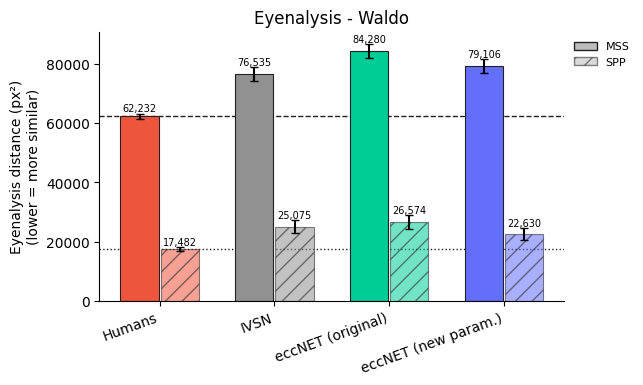

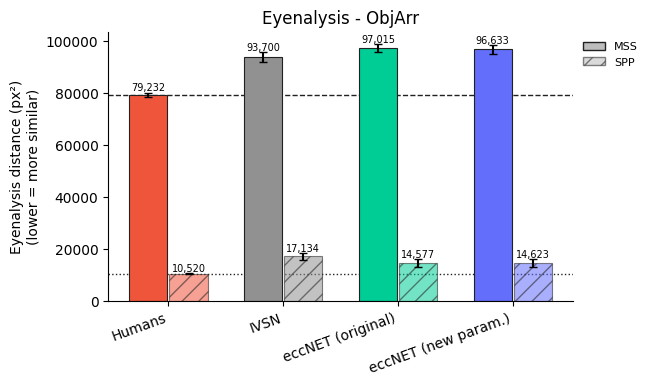

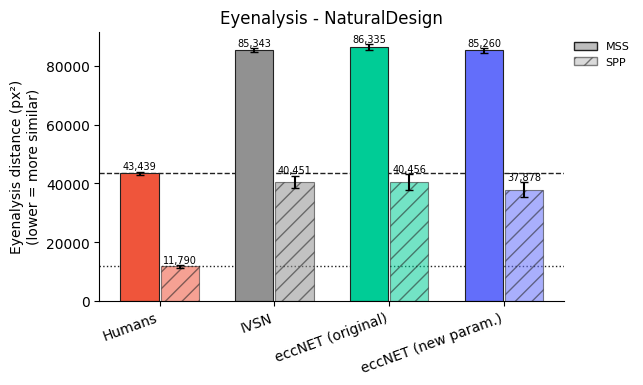

In [8]:
for dataset in DATASETS:
    plot_metric(dataset, "Eyenalysis")

### 7.2 Sequence similarity (ScanMatch, DTW, DTW normalized)

These metrics align the two fixation **sequences** in order:
- **ScanMatch** compares the sequences of 12×8 grid cells (coarse; small spatial offsets do not matter).
- **DTW** sums the pixel distances along the best monotonic alignment. Every fixation of both scanpaths must be aligned, so extra fixations cost, i.e. DTW is length-sensitive.
- **DTW normalized** is the same alignment, expressed as the mean distance per aligned pair.

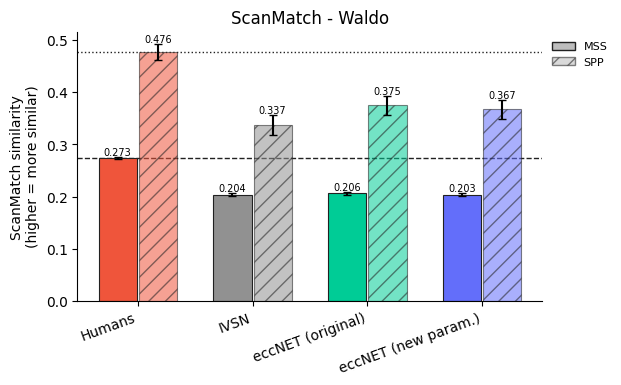

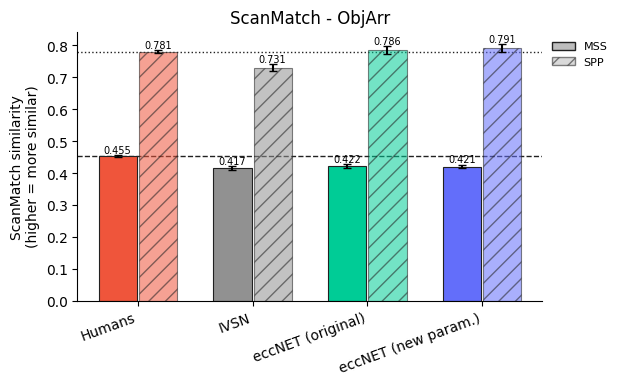

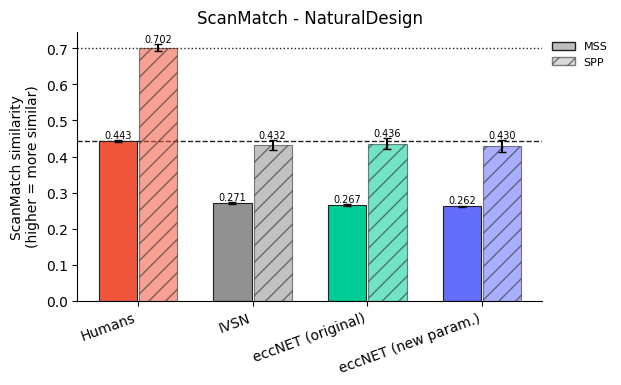

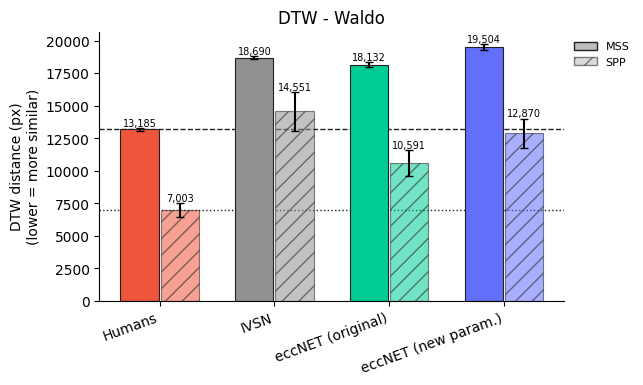

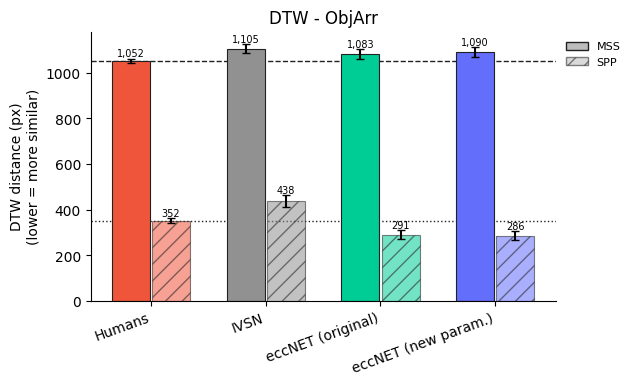

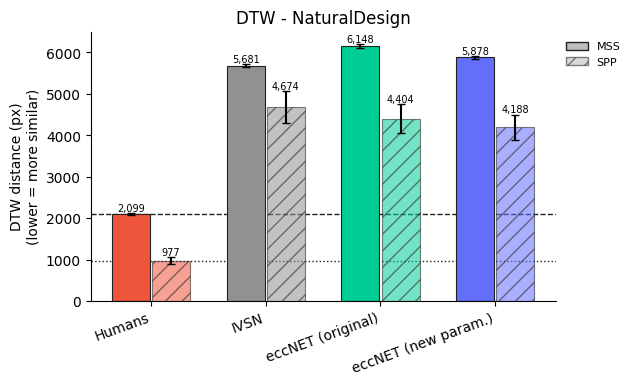

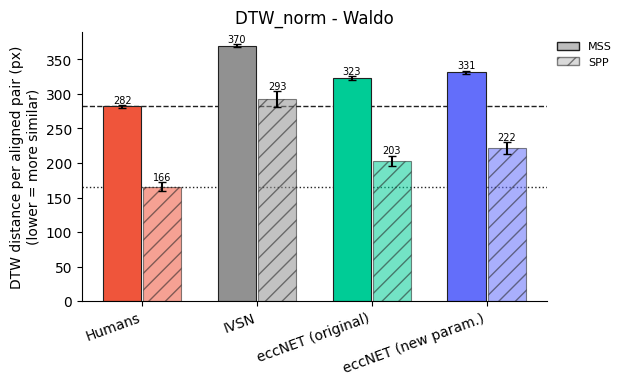

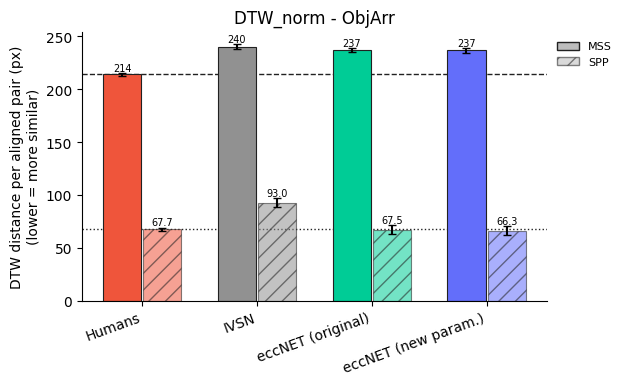

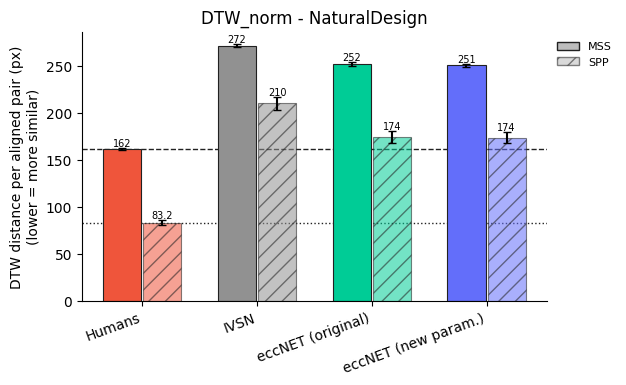

In [9]:
for metric_name in ["ScanMatch", "DTW", "DTW_norm"]:
    for dataset in DATASETS:
        plot_metric(dataset, metric_name)

### 7.3 Search efficiency

How quickly each source finds the target, independent of any scanpath metric. Per dataset:
- **Left:** cumulative search performance, i.e. the share of trials in which the target was found within ≤ k fixations (from `out/<dataset>/cp/`). Trials truncated at `NumFix` count as not found. Humans are pooled over all subjects × stimuli.
- **Middle:** number of fixations until the target was found (found trials only), mean ± SEM over trials.
- **Right:** saccade amplitude in px (per trial the mean distance between consecutive fixations), mean ± SEM over trials.

Fixation counts come from the raw files and therefore include the start fixation (also on ObjArr, identically for all sources). Saccade amplitudes are computed from the loaded fixations of Section 3, i.e. on ObjArr after the slot mapping and without the start fixation.

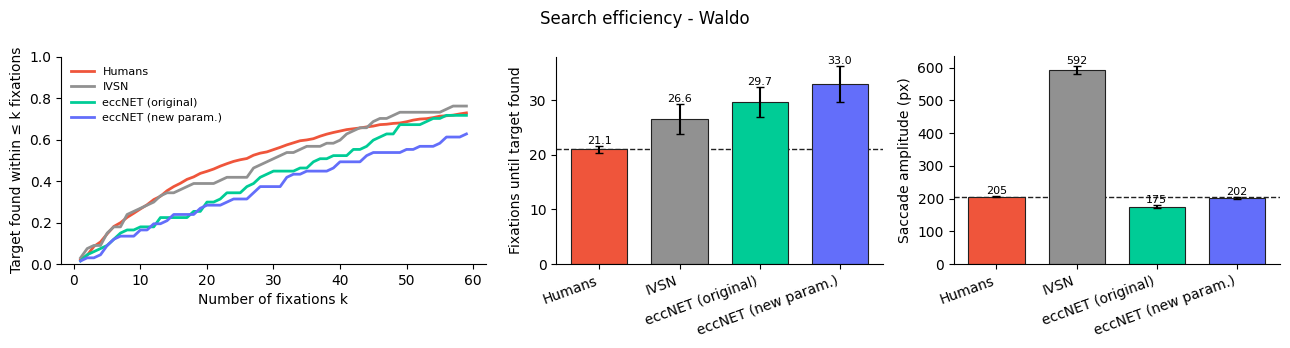

,found rate,fixations until found,saccade amplitude (px)
Humans,0.752,21.054,205.252
IVSN,0.836,26.589,592.332
eccNET (original),0.776,29.654,175.247
eccNET (new param.),0.746,33.000,201.562


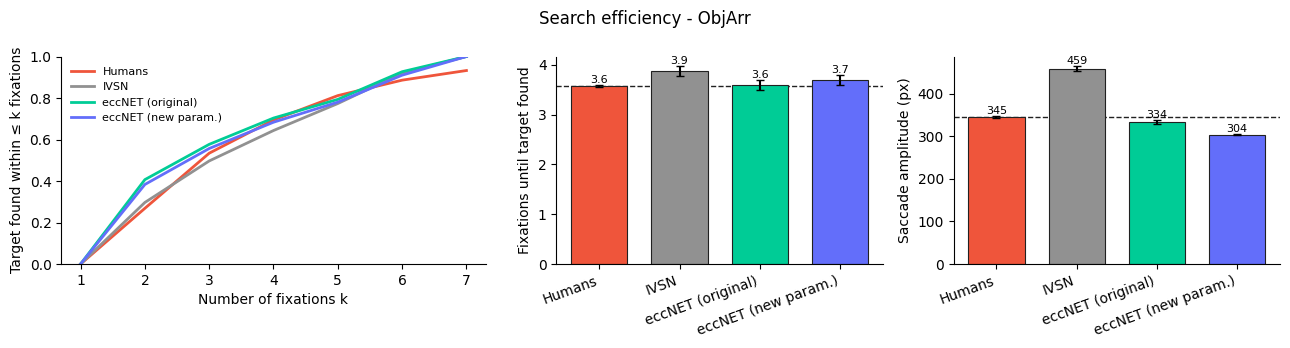

,found rate,fixations until found,saccade amplitude (px)
Humans,0.932,3.574,345.189
IVSN,1.000,3.870,458.752
eccNET (original),1.000,3.593,333.750
eccNET (new param.),1.000,3.687,303.922


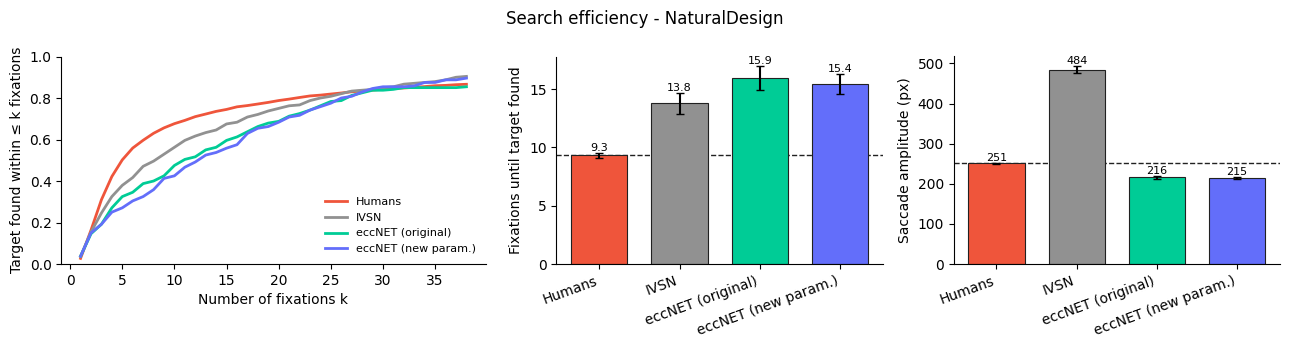

,found rate,fixations until found,saccade amplitude (px)
Humans,0.901,9.312,251.160
IVSN,0.979,13.779,484.294
eccNET (original),0.971,15.948,216.049
eccNET (new param.),0.967,15.422,214.513


In [10]:
STEMS = {HUMAN_LABEL: HUMAN_STEM, **MODELS}


def found_at(dataset, stem):
    """1-based fixation index at which the target was found, NaN if it was not found."""
    cp = np.load(SACCADE_DIR / "out" / dataset / "cp" / f"CP_{stem}.npy")
    return np.where(cp.sum(axis=1) > 0, cp.argmax(axis=1) + 1, np.nan)


def saccade_amplitudes(fix, I):
    """Mean saccade amplitude (px) per trial; NaN for trials with a single fixation."""
    return np.array([np.linalg.norm(np.diff(to_xy(f, n), axis=0), axis=1).mean() if n > 1 else np.nan
                     for f, n in zip(fix, I)])


def _bar_panel(ax, values, ylabel):
    labels = list(values)
    stats = [_mean_sem(v[~np.isnan(v)]) for v in values.values()]
    means, sems = [st["mean"] for st in stats], [st["sem"] for st in stats]
    x = np.arange(len(labels))
    ax.bar(x, means, 0.7, yerr=sems, capsize=3, color=[COLORS[l] for l in labels],
           edgecolor="#212121", linewidth=0.8)
    ax.axhline(means[0], color="#212121", linewidth=1, linestyle="--", zorder=0)
    for xi, m, se in zip(x, means, sems):
        ax.text(xi, m + se, _value_label(m), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, labels, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    return means


def plot_search_efficiency(dataset):
    found = {label: found_at(dataset, stem) for label, stem in STEMS.items()}
    loaded = {HUMAN_LABEL: data[dataset]["human_all"], **data[dataset]["models"]}
    amplitude = {label: saccade_amplitudes(*loaded[label]) for label in STEMS}

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    k_max = int(np.nanpercentile(np.concatenate(list(found.values())), 95))
    k = np.arange(1, k_max + 1)
    for label, f in found.items():
        axes[0].plot(k, [(f <= kk).mean() for kk in k], color=COLORS[label], linewidth=2, label=label)
    axes[0].set_xlabel("Number of fixations k")
    axes[0].set_ylabel("Target found within ≤ k fixations")
    axes[0].set_ylim(0, 1)
    axes[0].spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)

    fix_means = _bar_panel(axes[1], found, "Fixations until target found")
    amp_means = _bar_panel(axes[2], amplitude, "Saccade amplitude (px)")
    fig.suptitle(f"Search efficiency - {dataset}")
    fig.tight_layout()
    fig.savefig(OUT_DIR / dataset / "search_efficiency.pdf", bbox_inches="tight")
    plt.show()

    table = pd.DataFrame({
        "found rate": {label: np.mean(~np.isnan(f)) for label, f in found.items()},
        "fixations until found": dict(zip(STEMS, fix_means)),
        "saccade amplitude (px)": dict(zip(STEMS, amp_means)),
    })
    table.to_csv(OUT_DIR / dataset / "search_efficiency.csv")
    display(table.round(3))


for dataset in DATASETS:
    plot_search_efficiency(dataset)

### Overview table

Mean score per metric and source (plus the SPP score if enabled). `rank` orders the sources from most to least human-like (1 = most similar to humans), so you can see at a glance whether the metrics agree on the ranking.

In [11]:
for dataset in DATASETS:
    overview = {}
    for metric_name in METRICS:
        higher_is_better = METRICS[metric_name]["higher_is_better"]
        for key, name in [("mean", "mean"), ("spp", "SPP")] if SPP else [("mean", "mean")]:
            score = summaries[dataset, metric_name, key]["mean"]
            overview[(metric_name, name)] = score
            overview[(metric_name, f"{name} rank")] = score.rank(ascending=not higher_is_better).astype(int)
    print(dataset)
    display(pd.DataFrame(overview))

Waldo


ScanMatch                                 Eyenalysis  \
                         mean mean rank       SPP SPP rank          mean   
Humans               0.273015         1  0.476360        1  62231.501787   
IVSN                 0.203784         3  0.336703        4  76535.351574   
eccNET (original)    0.206298         2  0.374595        2  84280.274899   
eccNET (new param.)  0.203435         4  0.366880        3  79106.307194   

                                                               DTW            \
                    mean rank           SPP SPP rank          mean mean rank   
Humans                      1  17482.379856        1  13184.988315         1   
IVSN                        2  25074.543086        3  18690.300129         3   
eccNET (original)           4  26573.684701        4  18132.193446         2   
eccNET (new param.)         3  22630.128221        2  19503.748200         4   

                                              DTW_norm                        \
                              SPP SPP rank        mean mean rank         SPP   
Humans                7003.108679        1  282.095895         1  165.912452   
IVSN                 14550.854699        4  369.996268         4  292.707294   
eccNET (original)    10591.278823        2  323.483697         2  203.420473   
eccNET (new param.)  12869.932148        3  331.282445         3  222.059730   

                              
                    SPP rank  
Humans                     1  
IVSN                       4  
eccNET (original)          2  
eccNET (new param.)        3

ObjArr


ScanMatch                                 Eyenalysis  \
                         mean mean rank       SPP SPP rank          mean   
Humans               0.454702         1  0.781011        3  79232.078201   
IVSN                 0.417213         4  0.730748        4  93700.276667   
eccNET (original)    0.422347         2  0.785764        2  97014.837037   
eccNET (new param.)  0.421126         3  0.791115        1  96633.192963   

                                                              DTW            \
                    mean rank           SPP SPP rank         mean mean rank   
Humans                      1  10519.818889        1  1052.022368         1   
IVSN                        2  17134.405556        4  1104.986511         4   
eccNET (original)           4  14577.494444        2  1082.655211         2   
eccNET (new param.)         3  14622.905556        3  1089.761020         3   

                                            DTW_norm                       \
                            SPP SPP rank        mean mean rank        SPP   
Humans               351.533537        3  214.217348         1  67.709039   
IVSN                 438.285685        4  240.033712         4  92.995045   
eccNET (original)    291.431170        2  236.899743         3  67.508815   
eccNET (new param.)  285.571127        1  236.756707         2  66.335146   

                              
                    SPP rank  
Humans                     3  
IVSN                       4  
eccNET (original)          2  
eccNET (new param.)        1

NaturalDesign


ScanMatch                                 Eyenalysis  \
                         mean mean rank       SPP SPP rank          mean   
Humans               0.443232         1  0.701701        1  43439.429296   
IVSN                 0.271247         2  0.431909        3  85343.310003   
eccNET (original)    0.266807         3  0.435944        2  86334.872918   
eccNET (new param.)  0.262011         4  0.429692        4  85259.795270   

                                                              DTW            \
                    mean rank           SPP SPP rank         mean mean rank   
Humans                      1  11790.067603        1  2098.905865         1   
IVSN                        3  40451.460680        3  5681.211116         2   
eccNET (original)           4  40455.898800        4  6147.930804         4   
eccNET (new param.)         2  37878.080120        2  5877.535724         3   

                                             DTW_norm                        \
                             SPP SPP rank        mean mean rank         SPP   
Humans                977.264670        1  161.937687         1   83.187186   
IVSN                 4673.577655        4  272.013227         4  210.396644   
eccNET (original)    4403.810117        3  252.335945         3  174.341010   
eccNET (new param.)  4187.777998        2  250.903804         2  173.816573   

                              
                    SPP rank  
Humans                     1  
IVSN                       4  
eccNET (original)          3  
eccNET (new param.)        2

## 8. Notes

1. All three datasets (Waldo, ObjArr, NaturalDesign) have 15 subjects (1005 / 67, 4500 / 300, 3600 / 240).
2. Section 6 only applies where an `ss_score_py/` cache exists.
3. The SPP add-on needs at least 2 subjects per dataset (leave-one-out for the human baseline).
4. `eccNET_altParamSaccade.npy` (Waldo, NaturalDesign) is bit-identical to the original `eccNET.npy` and is therefore not used; `eccNET_altParam` is the run with the new parametrization.
5. ObjArr: `score_analysis.py` uses 544×544 as the ScanMatch resolution for ObjArr. The stored coordinates go up to 1190, so most fixations would be clipped into the border bins. That setting is therefore not used here. ObjArr is scored on the 1280×1024 screen after the slot mapping.